# Feedforward Neural Networks: A Complete Walkthrough

## Introduction

A **feedforward neural network** (also called a **multilayer perceptron** or MLP) is the most basic type of artificial neural network. Information flows in one direction—from input to output—without any loops or cycles.

### What We'll Revisit/Cover:
1. Basic concepts and terminology
2. Single neuron (perceptron) walkthrough
3. Forward propagation step-by-step
4. Activation functions
5. Backpropagation (learning)
6. Complete implementation from scratch
7. Real examples with visualization

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
np.random.seed(42)

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

# Part 1: Understanding a Single Neuron

## The Building Block

A single neuron is the fundamental unit. It:
1. Takes multiple inputs
2. Multiplies each by a weight
3. Adds them up (plus a bias)
4. Applies an activation function

### Mathematical Formula:

```
z = w₁x₁ + w₂x₂ + ... + wₙxₙ + b
output = activation(z)
```

Or in vector form:
```
z = w·x + b
output = activation(z)
```

### Visual Representation:

```
Inputs          Weights         
  x₁ ─────────── w₁ ─┐
                     ├──→ Σ ──→ activation(z) ──→ output
  x₂ ─────────── w₂ ─┘      
                     ↑
                  bias (b)
```

$$
z = \sum_{i}^N (w_i \cdot x_i) + b \\
z = \sum_{i = 1}^{N = 2} (w_1 \cdot x_1) + (w_2 \cdot x_2) + b \\
output = activation(z)
$$


### Wrong representation (aka, do not do):

$$ 
z_1 = (w_1 \cdot x_1) + b \\
a_1 = activation(z_1)
$$

$$
z_2 = (w_2 \cdot x_2) + b \\
a_2 = activation(z_2)
$$

In [2]:
# Simple example: Single neuron
def single_neuron(inputs, weights, bias):
    """
    Compute output of a single neuron.
    
    Args:
        inputs: array of input values [x1, x2, ...]
        weights: array of weights [w1, w2, ...]
        bias: bias value (scalar)
    
    Returns:
        output: neuron output (before activation)
    """
    # Weighted sum
    z = np.dot(weights, inputs) + bias
    return z

# Example
print("Single Neuron Example:")
print("="*60)

inputs = np.array([1.0, 2.0, 3.0])
weights = np.array([0.5, -0.3, 0.8])
bias = 0.1

print(f"\nInputs:  {inputs}")
print(f"Weights: {weights}")
print(f"Bias:    {bias}")

# Manual calculation
print("\nManual calculation:")
step1 = inputs[0] * weights[0]
step2 = inputs[1] * weights[1]
step3 = inputs[2] * weights[2]
print(f"  x₁ × w₁ = {inputs[0]} × {weights[0]} = {step1}")
print(f"  x₂ × w₂ = {inputs[1]} × {weights[1]} = {step2}")
print(f"  x₃ × w₃ = {inputs[2]} × {weights[2]} = {step3}")
print(f"  bias = {bias}")
print(f"  Sum = {step1} + {step2} + {step3} + {bias} = {step1 + step2 + step3 + bias}")

# Using function
output = single_neuron(inputs, weights, bias)
print(f"\nFunction output: {output}")

print("\nThis is the 'z' value before activation!")

Single Neuron Example:

Inputs:  [1. 2. 3.]
Weights: [ 0.5 -0.3  0.8]
Bias:    0.1

Manual calculation:
  x₁ × w₁ = 1.0 × 0.5 = 0.5
  x₂ × w₂ = 2.0 × -0.3 = -0.6
  x₃ × w₃ = 3.0 × 0.8 = 2.4000000000000004
  bias = 0.1
  Sum = 0.5 + -0.6 + 2.4000000000000004 + 0.1 = 2.4000000000000004

Function output: 2.4000000000000004

This is the 'z' value before activation!


# Part 2: Activation Functions

## Why Activation Functions?

Without activation functions, a neural network would just be a linear function, no matter how many layers! Activation functions introduce **non-linearity** (but remember even though Logistic Regression uses sigmoid funciton, it is still a linear classifier; Why?), allowing networks to learn complex patterns.

## Common Activation Functions

### 1. Sigmoid
```
σ(z) = 1 / (1 + e^(-z))
```
- Output range: (0, 1)
- Used for: Binary classification, output layer
- Problem: Vanishing gradients

### 2. Tanh (Hyperbolic Tangent)
```
tanh(z) = (e^z - e^(-z)) / (e^z + e^(-z))
```
- Output range: (-1, 1)
- Used for: Hidden layers (better than sigmoid)
- Problem: Still suffers from vanishing gradients

### 3. ReLU (Rectified Linear Unit)
```
ReLU(z) = max(0, z)
```
- Output range: [0, ∞)
- Used for: Hidden layers (most popular!)
- Advantages: Fast, simple, works well
- Problem: Dead neurons (can't recover from negative)

### 4. Leaky ReLU
```
LeakyReLU(z) = max(0.01z, z)
```
- Output range: (-∞, ∞)
- Fixes "dead ReLU" problem (ReLU outputs 0 for anything with a negative value; this means that sometimes it might output 0 for each training example. Dangerous!)

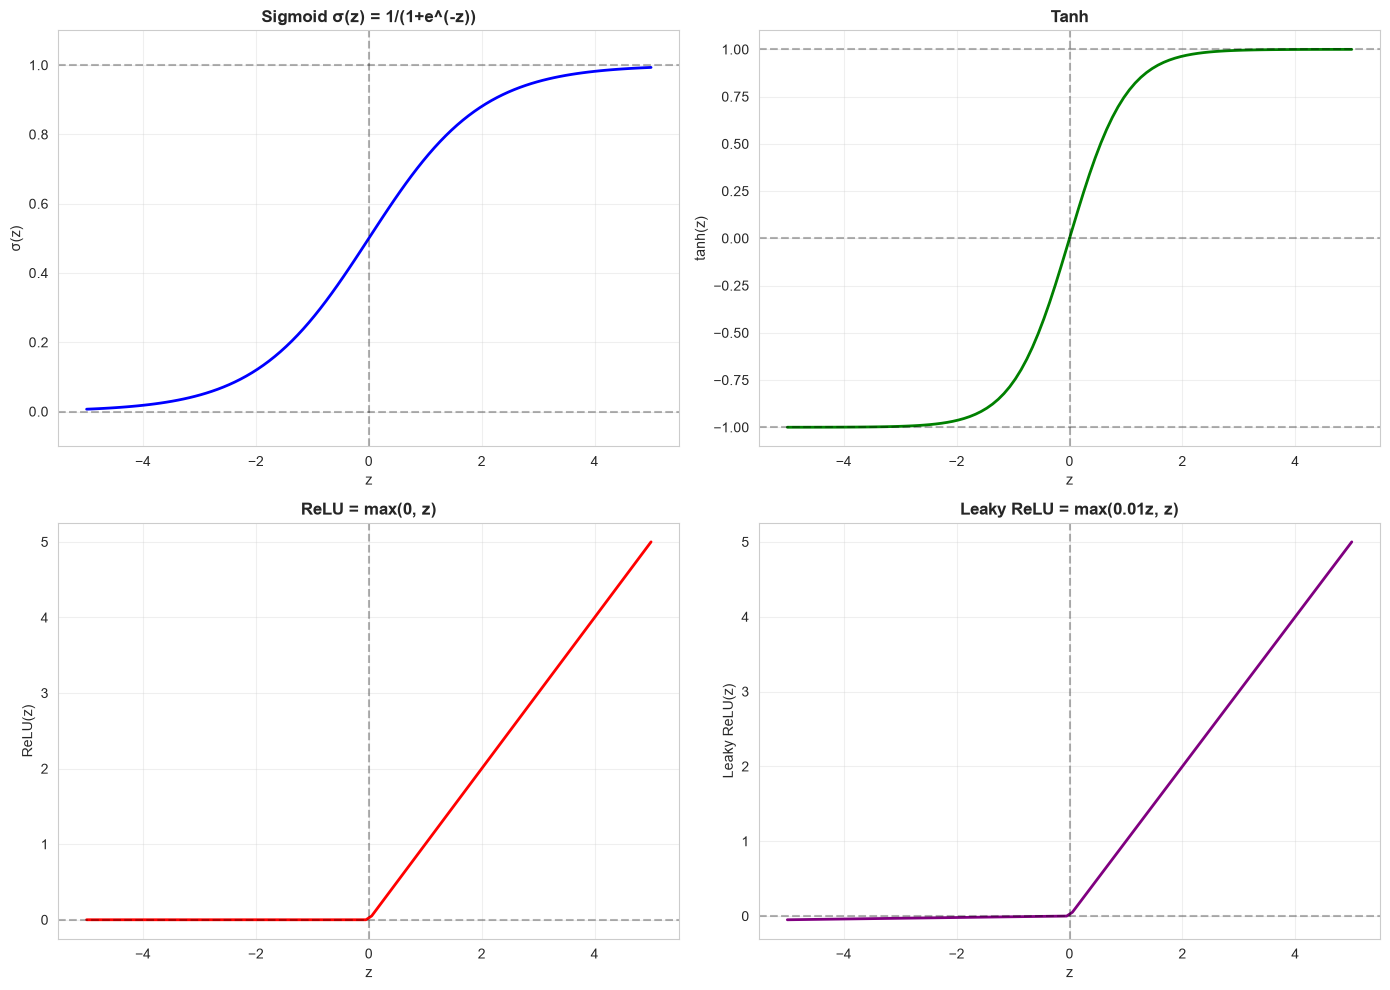

Key Observations:
   • Sigmoid: Squashes to (0, 1) - good for probabilities
   • Tanh: Squashes to (-1, 1) - zero-centered
   • ReLU: Simple, fast, most popular for hidden layers
   • Leaky ReLU: Fixes dead ReLU problem with small negative slope


In [3]:
# Implement activation functions
def sigmoid(z):
    """Sigmoid activation function."""
    return 1 / (1 + np.exp(-z))

def tanh(z):
    """Tanh activation function."""
    return np.tanh(z)

def relu(z):
    """ReLU activation function."""
    return np.maximum(0, z)

def leaky_relu(z, alpha=0.01):
    """Leaky ReLU activation function."""
    return np.where(z > 0, z, alpha * z)

# Visualize activation functions
z = np.linspace(-5, 5, 100)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Sigmoid
ax = axes[0, 0]
ax.plot(z, sigmoid(z), linewidth=2, color='blue')
ax.axhline(y=0, color='black', linestyle='--', alpha=0.3)
ax.axhline(y=1, color='black', linestyle='--', alpha=0.3)
ax.axvline(x=0, color='black', linestyle='--', alpha=0.3)
ax.set_title('Sigmoid σ(z) = 1/(1+e^(-z))', fontsize=12, fontweight='bold')
ax.set_xlabel('z')
ax.set_ylabel('σ(z)')
ax.grid(True, alpha=0.3)
ax.set_ylim(-0.1, 1.1)

# Tanh
ax = axes[0, 1]
ax.plot(z, tanh(z), linewidth=2, color='green')
ax.axhline(y=0, color='black', linestyle='--', alpha=0.3)
ax.axhline(y=1, color='black', linestyle='--', alpha=0.3)
ax.axhline(y=-1, color='black', linestyle='--', alpha=0.3)
ax.axvline(x=0, color='black', linestyle='--', alpha=0.3)
ax.set_title('Tanh', fontsize=12, fontweight='bold')
ax.set_xlabel('z')
ax.set_ylabel('tanh(z)')
ax.grid(True, alpha=0.3)
ax.set_ylim(-1.1, 1.1)

# ReLU
ax = axes[1, 0]
ax.plot(z, relu(z), linewidth=2, color='red')
ax.axhline(y=0, color='black', linestyle='--', alpha=0.3)
ax.axvline(x=0, color='black', linestyle='--', alpha=0.3)
ax.set_title('ReLU = max(0, z)', fontsize=12, fontweight='bold')
ax.set_xlabel('z')
ax.set_ylabel('ReLU(z)')
ax.grid(True, alpha=0.3)

# Leaky ReLU
ax = axes[1, 1]
ax.plot(z, leaky_relu(z), linewidth=2, color='purple')
ax.axhline(y=0, color='black', linestyle='--', alpha=0.3)
ax.axvline(x=0, color='black', linestyle='--', alpha=0.3)
ax.set_title('Leaky ReLU = max(0.01z, z)', fontsize=12, fontweight='bold')
ax.set_xlabel('z')
ax.set_ylabel('Leaky ReLU(z)')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Key Observations:")
print("   • Sigmoid: Squashes to (0, 1) - good for probabilities")
print("   • Tanh: Squashes to (-1, 1) - zero-centered")
print("   • ReLU: Simple, fast, most popular for hidden layers")
print("   • Leaky ReLU: Fixes dead ReLU problem with small negative slope")

# Part 3: Forward Propagation - Step by Step

## Network Architecture

Let's build a simple 3-layer network:
- **Input layer**: 2 neurons (features)
- **Hidden layer**: 3 neurons
- **Output layer**: 1 neuron

```
Input Layer    Hidden Layer    Output Layer
    (2)            (3)              (1)

    x₁ ────┐
           ├──→ h₁ ─┐
    x₂ ────┤         ├──→ y
           ├──→ h₂ ─┤
           └──→ h₃ ─┘
```

## Forward Pass Steps:

1. **Input → Hidden Layer**
   ```
   Z₁ = W₁·X + b₁
   A₁ = activation(Z₁)
   ```

   $$
   Z_1 = \sum_{i=1}^N \sum_{j=1}^N (W_i \cdot X_j) + b_1 \\
   Z_1 = \sum_{i=1}^N \sum_{j=1}^N (W_1 \cdot x_1) + (W_1 \cdot x_2) + b_1 \\
   A_1 = activation(Z_1)
   $$

2. **Hidden → Output Layer**
   ```
   Z₂ = W₂·A₁ + b₂
   A₂ = activation(Z₂)
   ```

   $$
   Z_2 = \sum_{i=1}^N \sum_{j=1}^N (W_2 \cdot x_1) + (W_2 \cdot x_2) + b_1 \\
   A_2 = activation(Z_1)
   $$

Where:
- W = weights matrix
- b = bias vector
- Z = pre-activation (weighted sum)
- A = activation (after applying activation function)

In [4]:
# Manual forward propagation example
print("Forward Propagation - Step by Step")
print("="*60)

# Define network architecture
input_size = 2
hidden_size = 3
output_size = 1

print(f"\nNetwork Architecture: {input_size} → {hidden_size} → {output_size}")

# Initialize weights and biases (small random values)
W1 = np.random.randn(hidden_size, input_size) * 0.5
b1 = np.zeros((hidden_size, 1))

W2 = np.random.randn(output_size, hidden_size) * 0.5
b2 = np.zeros((output_size, 1))

print(f"\nWeights and Biases:")
print(f"W1 shape: {W1.shape} (hidden × input)")
print(f"b1 shape: {b1.shape}")
print(f"W2 shape: {W2.shape} (output × hidden)")
print(f"b2 shape: {b2.shape}")

# Sample input
X = np.array([[0.5], [0.8]])  # 2×1 column vector
print(f"\nInput X:\n{X}")
print(f"X shape: {X.shape}")

# Step 1: Input → Hidden Layer
print("\n" + "="*60)
print("STEP 1: Input → Hidden Layer")
print("="*60)

Z1 = np.dot(W1, X) + b1
print(f"\nZ1 = W1·X + b1")
print(f"Z1 (pre-activation):\n{Z1}")
print(f"Z1 shape: {Z1.shape}")

A1 = relu(Z1)
print(f"\nA1 = ReLU(Z1)")
print(f"A1 (after activation):\n{A1}")
print(f"A1 shape: {A1.shape}")

# Step 2: Hidden → Output Layer
print("\n" + "="*60)
print("STEP 2: Hidden → Output Layer")
print("="*60)

Z2 = np.dot(W2, A1) + b2
print(f"\nZ2 = W2·A1 + b2")
print(f"Z2 (pre-activation):\n{Z2}")
print(f"Z2 shape: {Z2.shape}")

A2 = sigmoid(Z2)
print(f"\nA2 = Sigmoid(Z2)")
print(f"A2 (final output):\n{A2}")
print(f"A2 shape: {A2.shape}")

print("\n" + "="*60)
print(f"Final prediction: {A2[0, 0]:.4f}")
print("="*60)

Forward Propagation - Step by Step

Network Architecture: 2 → 3 → 1

Weights and Biases:
W1 shape: (3, 2) (hidden × input)
b1 shape: (3, 1)
W2 shape: (1, 3) (output × hidden)
b2 shape: (1, 1)

Input X:
[[0.5]
 [0.8]]
X shape: (2, 1)

STEP 1: Input → Hidden Layer

Z1 = W1·X + b1
Z1 (pre-activation):
[[ 0.06887282]
 [ 0.77113408]
 [-0.15219313]]
Z1 shape: (3, 1)

A1 = ReLU(Z1)
A1 (after activation):
[[0.06887282]
 [0.77113408]
 [0.        ]]
A1 shape: (3, 1)

STEP 2: Hidden → Output Layer

Z2 = W2·A1 + b2
Z2 (pre-activation):
[[0.35027995]]
Z2 shape: (1, 1)

A2 = Sigmoid(Z2)
A2 (final output):
[[0.58668547]]
A2 shape: (1, 1)

Final prediction: 0.5867


# Part 4: Complete Neural Network Class

Now let's build a complete, reusable neural network class with:
- Forward propagation
- Backpropagation (learning)
- Training loop
- Prediction

In [5]:
class NeuralNetwork:
    """
    A simple feedforward neural network with one hidden layer.
    """
    
    def __init__(self, input_size, hidden_size, output_size, learning_rate=0.01):
        """
        Initialize the neural network.
        
        Args:
            input_size: Number of input features
            hidden_size: Number of neurons in hidden layer
            output_size: Number of output neurons
            learning_rate: Learning rate for gradient descent
        """
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.learning_rate = learning_rate
        
        # Initialize weights with small random values
        self.W1 = np.random.randn(hidden_size, input_size) * 0.5
        self.b1 = np.zeros((hidden_size, 1))
        
        self.W2 = np.random.randn(output_size, hidden_size) * 0.5
        self.b2 = np.zeros((output_size, 1))
        
        # For tracking training
        self.losses = []
    
    def relu(self, z):
        """ReLU activation function."""
        return np.maximum(0, z)
    
    def relu_derivative(self, z):
        """Derivative of ReLU."""
        return (z > 0).astype(float)
    
    def sigmoid(self, z):
        """Sigmoid activation function."""
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))  # Clip to prevent overflow
    
    def sigmoid_derivative(self, a):
        """Derivative of sigmoid (using activation value)."""
        return a * (1 - a)
    
    def forward(self, X):
        """
        Forward propagation.
        
        Args:
            X: Input data (input_size × n_samples)
        
        Returns:
            A2: Final output (output_size × n_samples)
            cache: Dictionary containing intermediate values
        """
        # Input → Hidden
        Z1 = np.dot(self.W1, X) + self.b1
        A1 = self.relu(Z1)
        
        # Hidden → Output
        Z2 = np.dot(self.W2, A1) + self.b2
        A2 = self.sigmoid(Z2)
        
        # Store for backpropagation
        cache = {
            'Z1': Z1, 'A1': A1,
            'Z2': Z2, 'A2': A2,
            'X': X
        }
        
        return A2, cache
    
    def compute_loss(self, A2, Y):
        """
        Compute binary cross-entropy loss.
        
        Args:
            A2: Predictions (output_size × n_samples)
            Y: True labels (output_size × n_samples)
        
        Returns:
            loss: Average loss
        """
        m = Y.shape[1]  # Number of samples
        
        # Binary cross-entropy
        loss = -np.mean(Y * np.log(A2 + 1e-8) + (1 - Y) * np.log(1 - A2 + 1e-8))
        
        return loss
    
    def backward(self, cache, Y):
        """
        Backpropagation.
        
        Args:
            cache: Dictionary from forward pass
            Y: True labels (output_size × n_samples)
        
        Returns:
            gradients: Dictionary of gradients
        """
        m = Y.shape[1]  # Number of samples
        
        # Get values from cache
        Z1, A1 = cache['Z1'], cache['A1']
        Z2, A2 = cache['Z2'], cache['A2']
        X = cache['X']
        
        # Output layer gradients
        dZ2 = A2 - Y  # Derivative of loss w.r.t. Z2
        dW2 = (1/m) * np.dot(dZ2, A1.T)
        db2 = (1/m) * np.sum(dZ2, axis=1, keepdims=True)
        
        # Hidden layer gradients
        dA1 = np.dot(self.W2.T, dZ2)
        dZ1 = dA1 * self.relu_derivative(Z1)
        dW1 = (1/m) * np.dot(dZ1, X.T)
        db1 = (1/m) * np.sum(dZ1, axis=1, keepdims=True)
        
        gradients = {
            'dW1': dW1, 'db1': db1,
            'dW2': dW2, 'db2': db2
        }
        
        return gradients
    
    def update_parameters(self, gradients):
        """
        Update weights and biases using gradient descent.
        
        Args:
            gradients: Dictionary of gradients
        """
        self.W1 -= self.learning_rate * gradients['dW1']
        self.b1 -= self.learning_rate * gradients['db1']
        self.W2 -= self.learning_rate * gradients['dW2']
        self.b2 -= self.learning_rate * gradients['db2']
    
    def train(self, X, Y, epochs=1000, verbose=True):
        """
        Train the neural network.
        
        Args:
            X: Training data (input_size × n_samples)
            Y: Training labels (output_size × n_samples)
            epochs: Number of training iterations
            verbose: Whether to print progress
        """
        for epoch in range(epochs):
            # Forward pass
            A2, cache = self.forward(X)
            
            # Compute loss
            loss = self.compute_loss(A2, Y)
            self.losses.append(loss)
            
            # Backward pass
            gradients = self.backward(cache, Y)
            
            # Update parameters
            self.update_parameters(gradients)
            
            # Print progress
            if verbose and (epoch % 100 == 0 or epoch == epochs - 1):
                accuracy = np.mean((A2 > 0.5) == Y) * 100
                print(f"Epoch {epoch:4d} | Loss: {loss:.4f} | Accuracy: {accuracy:.2f}%")
    
    def predict(self, X):
        """
        Make predictions.
        
        Args:
            X: Input data (input_size × n_samples)
        
        Returns:
            predictions: Binary predictions (0 or 1)
        """
        A2, _ = self.forward(X)
        return (A2 > 0.5).astype(int)

print("Neural Network class created.")
print("Ready to train on data.")

Neural Network class created.
Ready to train on data.


# Part 5: Training on Real Data

Let's train our network on a simple binary classification problem (a fake example for now).

Generating Training Data...
Training data shape: (2, 200)
Training labels shape: (1, 200)
Class 0 samples: 100
Class 1 samples: 100


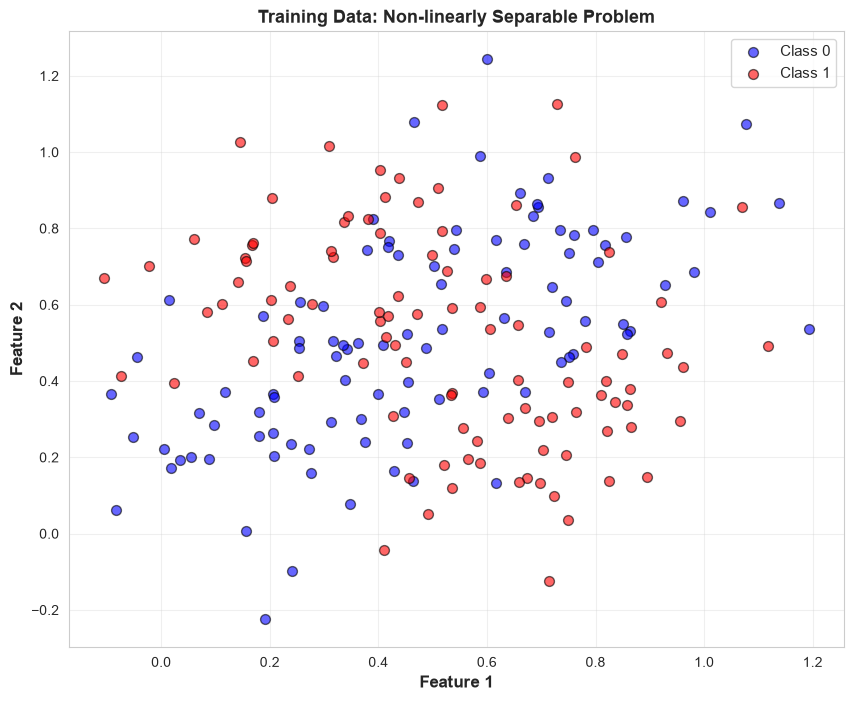


This is a non-linear problem - a straight line can't separate the classes.
   That's why we need a neural network with hidden layers.


In [6]:
# Generate synthetic data (XOR-like problem)
print("Generating Training Data...")
print("="*60)

# Create a non-linearly separable dataset
np.random.seed(42)
n_samples = 200

# Class 0: Corners (0,0) and (1,1)
X_class0_1 = np.random.randn(2, n_samples//4) * 0.2 + np.array([[0.3], [0.3]])
X_class0_2 = np.random.randn(2, n_samples//4) * 0.2 + np.array([[0.7], [0.7]])
X_class0 = np.hstack([X_class0_1, X_class0_2])
Y_class0 = np.zeros((1, n_samples//2))

# Class 1: Corners (0,1) and (1,0)
X_class1_1 = np.random.randn(2, n_samples//4) * 0.2 + np.array([[0.3], [0.7]])
X_class1_2 = np.random.randn(2, n_samples//4) * 0.2 + np.array([[0.7], [0.3]])
X_class1 = np.hstack([X_class1_1, X_class1_2])
Y_class1 = np.ones((1, n_samples//2))

# Combine
X_train = np.hstack([X_class0, X_class1])
Y_train = np.hstack([Y_class0, Y_class1])

# Shuffle
shuffle_idx = np.random.permutation(n_samples)
X_train = X_train[:, shuffle_idx]
Y_train = Y_train[:, shuffle_idx]

print(f"Training data shape: {X_train.shape}")
print(f"Training labels shape: {Y_train.shape}")
print(f"Class 0 samples: {np.sum(Y_train == 0)}")
print(f"Class 1 samples: {np.sum(Y_train == 1)}")

# Visualize data
plt.figure(figsize=(10, 8))
plt.scatter(X_train[0, Y_train[0] == 0], X_train[1, Y_train[0] == 0], 
           c='blue', label='Class 0', s=50, alpha=0.6, edgecolors='black')
plt.scatter(X_train[0, Y_train[0] == 1], X_train[1, Y_train[0] == 1], 
           c='red', label='Class 1', s=50, alpha=0.6, edgecolors='black')
plt.xlabel('Feature 1', fontsize=12, fontweight='bold')
plt.ylabel('Feature 2', fontsize=12, fontweight='bold')
plt.title('Training Data: Non-linearly Separable Problem', 
         fontsize=13, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.show()

print("\nThis is a non-linear problem - a straight line can't separate the classes.")
print("   That's why we need a neural network with hidden layers.")

In [7]:
# Create and train the neural network
print("Training Neural Network...")
print("="*60)

# Initialize network
nn = NeuralNetwork(
    input_size=2,      # 2 input features
    hidden_size=4,     # 4 hidden neurons
    output_size=1,     # 1 output (binary classification)
    learning_rate=0.5
)

print(f"\nNetwork architecture: {nn.input_size} → {nn.hidden_size} → {nn.output_size}")
print(f"Learning rate: {nn.learning_rate}")
print(f"\nTraining for 1000 epochs...\n")

# Train
nn.train(X_train, Y_train, epochs=1000, verbose=True)

print("\n✅ Training complete!")

Training Neural Network...

Network architecture: 2 → 4 → 1
Learning rate: 0.5

Training for 1000 epochs...

Epoch    0 | Loss: 0.6926 | Accuracy: 51.50%
Epoch  100 | Loss: 0.6799 | Accuracy: 59.50%
Epoch  200 | Loss: 0.6449 | Accuracy: 61.50%
Epoch  300 | Loss: 0.6068 | Accuracy: 62.50%
Epoch  400 | Loss: 0.5830 | Accuracy: 64.50%
Epoch  500 | Loss: 0.5714 | Accuracy: 65.50%
Epoch  600 | Loss: 0.5632 | Accuracy: 64.00%
Epoch  700 | Loss: 0.5570 | Accuracy: 64.50%
Epoch  800 | Loss: 0.5528 | Accuracy: 65.50%
Epoch  900 | Loss: 0.5498 | Accuracy: 65.50%
Epoch  999 | Loss: 0.5474 | Accuracy: 65.50%

✅ Training complete!


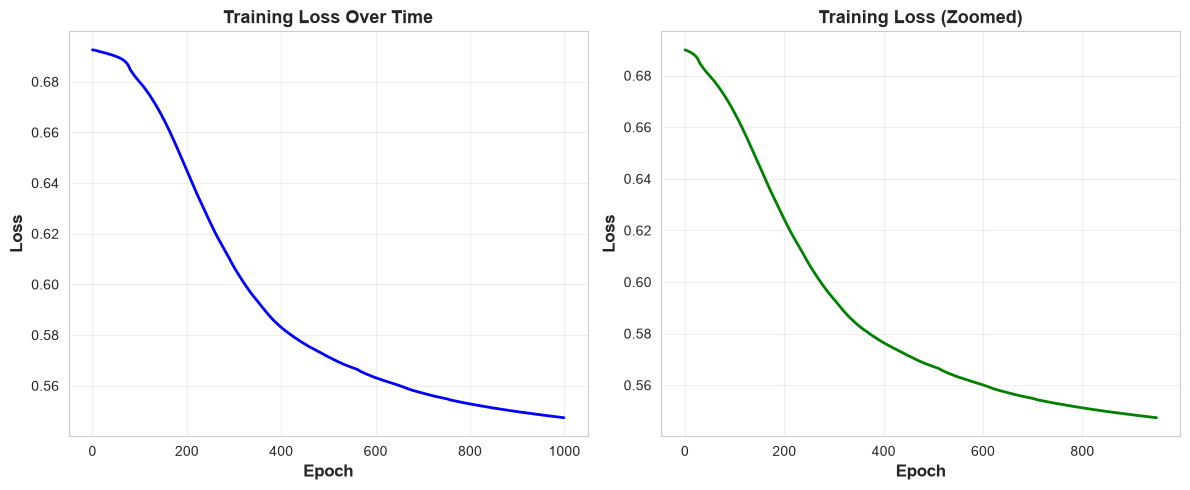


The loss decreases over time as the network learns.

The network is adjusting weights to minimize prediction errors.


In [8]:
# Visualize training progress
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(nn.losses, linewidth=2, color='blue')
plt.xlabel('Epoch', fontsize=12, fontweight='bold')
plt.ylabel('Loss', fontsize=12, fontweight='bold')
plt.title('Training Loss Over Time', fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(nn.losses[50:], linewidth=2, color='green')  # Zoom in after 50 epochs
plt.xlabel('Epoch', fontsize=12, fontweight='bold')
plt.ylabel('Loss', fontsize=12, fontweight='bold')
plt.title('Training Loss (Zoomed)', fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nThe loss decreases over time as the network learns.")
print("\nThe network is adjusting weights to minimize prediction errors.")

Visualizing Decision Boundary...


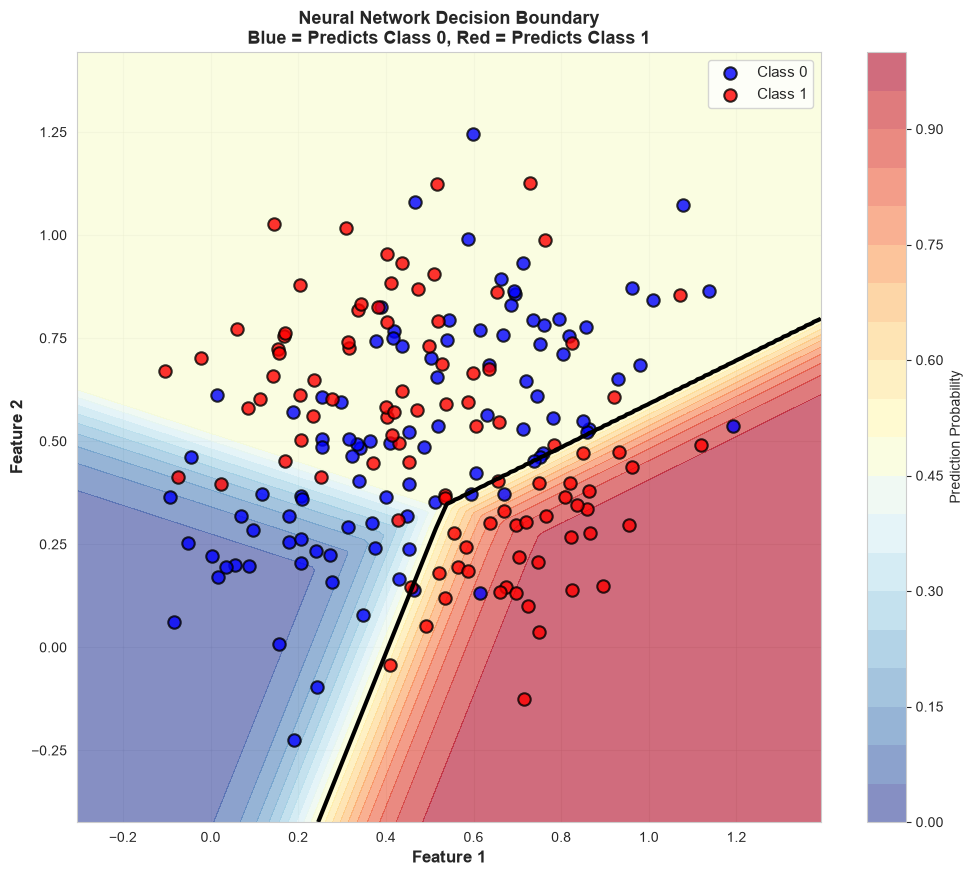


Final Training Accuracy: 65.50%

Notice how the network learned a non-linear decision boundary.

This wouldn't be possible with a simple linear classifier.


In [9]:
# Visualize decision boundary
print("Visualizing Decision Boundary...")
print("="*60)

# Create a mesh
x_min, x_max = X_train[0].min() - 0.2, X_train[0].max() + 0.2
y_min, y_max = X_train[1].min() - 0.2, X_train[1].max() + 0.2
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Predict on mesh
mesh_input = np.c_[xx.ravel(), yy.ravel()].T
Z, _ = nn.forward(mesh_input)
Z = Z.reshape(xx.shape)

# Plot
plt.figure(figsize=(12, 10))

# Decision boundary
plt.contourf(xx, yy, Z, levels=20, alpha=0.6, cmap='RdYlBu_r')
plt.colorbar(label='Prediction Probability')

# Decision line
plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=3)

# Data points
plt.scatter(X_train[0, Y_train[0] == 0], X_train[1, Y_train[0] == 0],
           c='blue', label='Class 0', s=80, alpha=0.8, edgecolors='black', linewidths=1.5)
plt.scatter(X_train[0, Y_train[0] == 1], X_train[1, Y_train[0] == 1],
           c='red', label='Class 1', s=80, alpha=0.8, edgecolors='black', linewidths=1.5)

plt.xlabel('Feature 1', fontsize=12, fontweight='bold')
plt.ylabel('Feature 2', fontsize=12, fontweight='bold')
plt.title('Neural Network Decision Boundary\nBlue = Predicts Class 0, Red = Predicts Class 1',
         fontsize=13, fontweight='bold')
plt.legend(fontsize=11, loc='upper right')
plt.grid(True, alpha=0.3)
plt.show()

# Calculate final accuracy
predictions = nn.predict(X_train)
accuracy = np.mean(predictions == Y_train) * 100

print(f"\nFinal Training Accuracy: {accuracy:.2f}%")
print("\nNotice how the network learned a non-linear decision boundary.")
print("\nThis wouldn't be possible with a simple linear classifier.")

- > Bottom left is more blue
- > Bottom right is more red
- > Top is a mix of both
- > I'd think the red is more misclassified vs the blue

# Part 6: Testing on New Data

In [ ]:
# Test on new points
print("Testing on New Data Points")
print("="*60)

# Create test points
test_points = np.array([
    [0.3, 0.3],  # Should be class 0
    [0.7, 0.7],  # Should be class 0
    [0.3, 0.7],  # Should be class 1; I'm seeing class 0
    [0.7, 0.3],  # Should be class 1
    [0.5, 0.5],  # Ambiguous (center)
]).T

print("\nTest Points:")
for i in range(test_points.shape[1]):
    point = test_points[:, i:i+1]
    prediction, _ = nn.forward(point)
    pred_class = int(prediction[0, 0] > 0.5)
 
    print(f"\nPoint {i+1}: ({point[0, 0]:.1f}, {point[1, 0]:.1f})")
    print(f"  Raw output: {prediction[0, 0]:.4f}")
    print(f"  Prediction: Class {pred_class}")

print("The network successfully classifies new, unseen data!")

Testing on New Data Points

Test Points:

Point 1: (0.3, 0.3)
  Raw output: 0.1840
  Prediction: Class 0

Point 2: (0.7, 0.7)
  Raw output: 0.4868
  Prediction: Class 0

Point 3: (0.3, 0.7)
  Raw output: 0.4868
  Prediction: Class 0

Point 4: (0.7, 0.3)
  Raw output: 0.8923
  Prediction: Class 1

Point 5: (0.5, 0.5)
  Raw output: 0.4868
  Prediction: Class 0
The network successfully classifies new, unseen data!
